In [7]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)

TensorFlow Version: 2.21.0
NumPy Version: 2.1.3


In [8]:
fashion_mnist = tf.keras.datasets.fashion_mnist
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [9]:
print("Training Images:", train_images.shape)
print("Training Labels:", train_labels.shape)

print("Testing Images:", test_images.shape)
print("Testing Labels:", test_labels.shape)

Training Images: (60000, 28, 28)
Training Labels: (60000,)
Testing Images: (10000, 28, 28)
Testing Labels: (10000,)


In [10]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

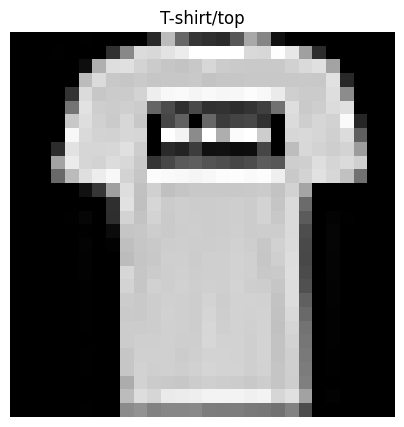

In [11]:
plt.figure(figsize=(5,5))

plt.imshow(train_images[1], cmap="grey")

plt.title(class_names[train_labels[1]])

plt.axis("off")

plt.show()

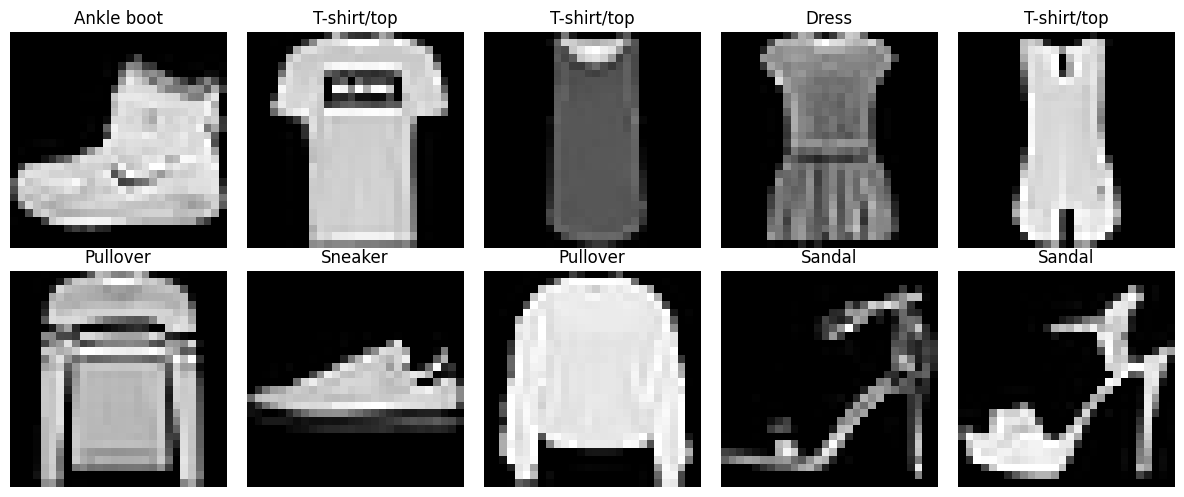

In [12]:
plt.figure(figsize=(12,5))
for  i in range(10):
  plt.subplot(2,5,i+1)
  plt.imshow(train_images[i],cmap="gray");
  plt.title(class_names[train_labels[i]])
  plt.axis("off")
plt.tight_layout()
plt.show()

In [13]:
print("Image Shape:", train_images[0].shape)

print("Pixel Values:")
print(train_images[0])

Image Shape: (28, 28)
Pixel Values:
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   1   0   0  13  73   0
    0   1   4   0   0   0   0   1   1   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3   0  36 136 127  62
   54   0   0   0   1   3   4   0   0   3]
 [  0   0   0   0   0   0   0   0   0   0   0   0   6   0 102 204 176 134
  144 123  23   0   0   0   0  12  10   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0 155 236 207 178
  107 156 161 109  64  23  77 130  72  15]
 [  0   0   0   0   0   0   0   0   0   0   0   1   0  69 207 223 218 216
  216 163 127 121 122 146 141  88 172  66]
 [  0   0   0   0   0   0   

In [14]:
train_images = train_images.astype("float32")/255.0
test_images = test_images.astype("float32")/255.0
print("Minimum Pixel Value:",train_images.min())
print("Maximum Pixel Value:",train_images.max())

Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


In [15]:
train_images = np.expand_dims(train_images, axis=-1)
test_images = np.expand_dims(test_images, axis=-1)

print("Training Shape:", train_images.shape)
print("Testing Shape:", test_images.shape)

Training Shape: (60000, 28, 28, 1)
Testing Shape: (10000, 28, 28, 1)


In [16]:
model = tf.keras.Sequential([

    # First Convolution Layer
    tf.keras.layers.Conv2D(
        32,
        (3, 3),
        activation='relu',
        input_shape=(28, 28, 1)
    ),

    # First Pooling Layer
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Second Convolution Layer
    tf.keras.layers.Conv2D(
        64,
        (3, 3),
        activation='relu'
    ),

    # Second Pooling Layer
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Convert feature maps into 1D
    tf.keras.layers.Flatten(),

    # Fully Connected Layer
    tf.keras.layers.Dense(128, activation='relu'),

    # Output Layer
    tf.keras.layers.Dense(10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [17]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
model.compile(

    optimizer='adam',

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']

)

In [19]:
history = model.fit(

    train_images,
    train_labels,

    epochs=10,

    batch_size=64,

    validation_split=0.2

)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 43s 55ms/step - accuracy: 0.8118 - loss: 0.5162 - val_accuracy: 0.8627 - val_loss: 0.3791
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 39s 52ms/step - accuracy: 0.8779 - loss: 0.3362 - val_accuracy: 0.8792 - val_loss: 0.3327
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 39s 52ms/step - accuracy: 0.8948 - loss: 0.2862 - val_accuracy: 0.8947 - val_loss: 0.2919
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 39s 53ms/step - accuracy: 0.9064 - loss: 0.2555 - val_accuracy: 0.9037 - val_loss: 0.2710
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 39s 52ms/step - accuracy: 0.9150 - loss: 0.2309 - val_accuracy: 0.9027 - val_loss: 0.2696
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 39s 52ms/step - accuracy: 0.9228 - loss: 0.2089 - val_accuracy: 0.9077 - val_loss: 0.2477
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 41s 55ms/step - accuracy: 0.9296 - loss: 0.1880 - val_accuracy: 0.9083 - val_loss: 0.2571
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 39s 52ms/step - accuracy: 0.9374 - loss: 0.1695 - 

In [20]:
test_loss, test_accuracy = model.evaluate(
    test_images,
    test_labels
)

print("Test Loss:", test_loss)

print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9090 - loss: 0.2673
Test Loss: 0.26726362109184265
Test Accuracy: 90.89999794960022 %


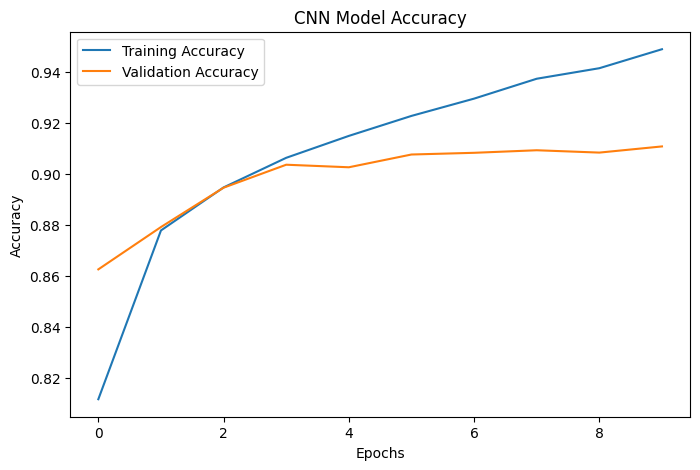

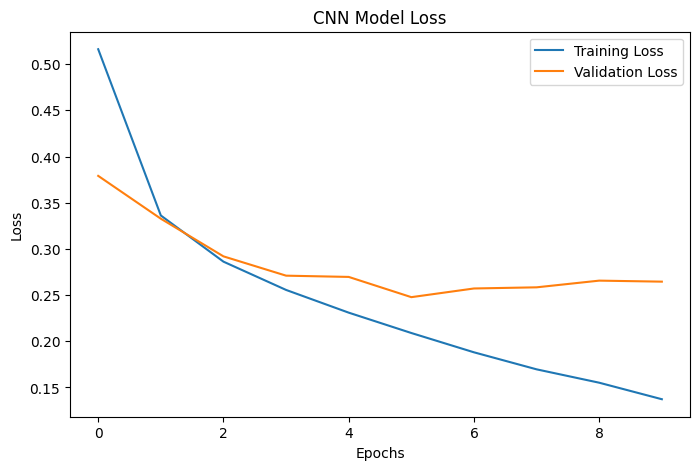

In [21]:
import matplotlib.pyplot as plt

# Accuracy Graph
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('CNN Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


# Loss Graph
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('CNN Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [22]:
model.save("fashion_cnn_model.keras")

print("Model saved successfully!")

Model saved successfully!


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


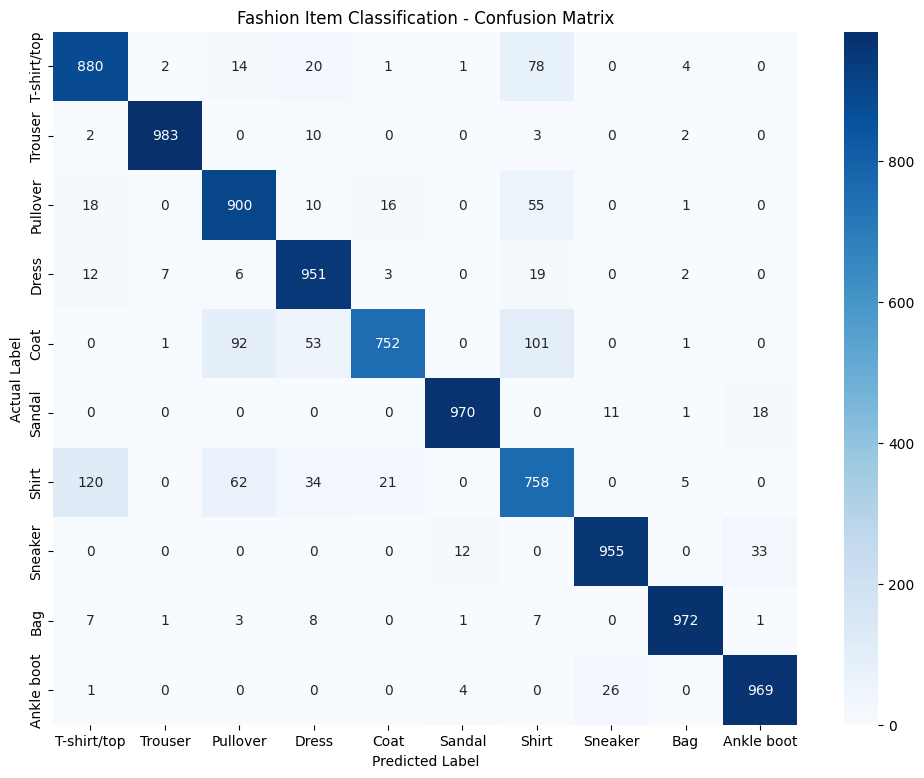

In [23]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

predictions = model.predict(test_images)

predicted_labels = np.argmax(predictions, axis=1)

cm = confusion_matrix(test_labels, predicted_labels)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Fashion Item Classification - Confusion Matrix")

plt.show()

In [24]:
print(classification_report(
    test_labels,
    predicted_labels,
    target_names=class_names
))

              precision    recall  f1-score   support

 T-shirt/top       0.85      0.88      0.86      1000
     Trouser       0.99      0.98      0.99      1000
    Pullover       0.84      0.90      0.87      1000
       Dress       0.88      0.95      0.91      1000
        Coat       0.95      0.75      0.84      1000
      Sandal       0.98      0.97      0.98      1000
       Shirt       0.74      0.76      0.75      1000
     Sneaker       0.96      0.95      0.96      1000
         Bag       0.98      0.97      0.98      1000
  Ankle boot       0.95      0.97      0.96      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



Actual Item: Dress
Predicted Item: Dress
Confidence: 99.99 %


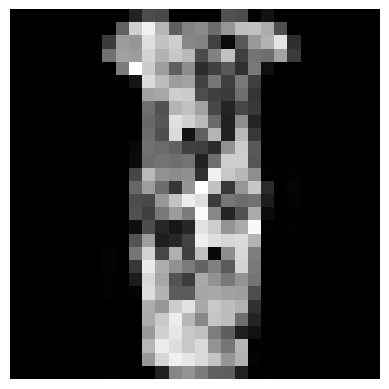

In [25]:
index = 100

plt.imshow(test_images[index].squeeze(), cmap='gray')
plt.axis('off')

prediction = model.predict(
    test_images[index:index+1],
    verbose=0
)

predicted_class = np.argmax(prediction)

print("Actual Item:", class_names[test_labels[index]])

print("Predicted Item:", class_names[predicted_class])

print("Confidence:", round(np.max(prediction)*100, 2), "%")

In [26]:
model.save("fashion_cnn_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [27]:
from google.colab import files
files.download("fashion_cnn_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>